In [1]:
from pathlib import Path
import os

REPO_URL = "https://github.com/jasmindamia/UTP-MACHINE-LEARNING.git"
REPO = Path("/content/UTP-MACHINE-LEARNING")

if not REPO.exists():
    !git clone {REPO_URL} /content/UTP-MACHINE-LEARNING
else:
    print("Repository already exists.")

DATA = REPO / "all_datasets"
EXPERIMENTS = REPO / "all_experiments"
MODELS = REPO / "models"

MODELS.mkdir(exist_ok=True)
EXPERIMENTS.mkdir(exist_ok=True)

print("Repository exists:", REPO.exists())
print("Datasets folder exists:", DATA.exists())
print("Datasets found:", len(list(DATA.glob("*.csv"))))
print("Dataset files:")
for file in sorted(DATA.iterdir()):
    print("-", file.name)

Cloning into '/content/UTP-MACHINE-LEARNING'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 35 (delta 8), reused 25 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 1.88 MiB | 14.47 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Repository exists: True
Datasets folder exists: True
Datasets found: 11
Dataset files:
- ames_housing_dataset.csv
- bike_sharing_dataset_day.csv
- bike_sharing_dataset_hour.csv
- breast_cancer_dataset.csv
- credit_card_fraud_dataset.csv
- heart_failure_dataset.csv
- mall_customers_dataset.csv
- medical_cost_personal_dataset.csv
- optical_recognition_handwritten_digits.zip
- red_wine_quality_dataset.csv
- student_performance_dataset.csv
- titanic_dataset.csv


# Lab 02: Supervised Learning I
## Regression, Classification, and the Machine Learning Workflow

**Course:** Machine Learning  
**Notebook:** Lab02_supervised_learning

### Objectives
- Build regression and classification pipelines.
- Evaluate models using appropriate metrics.
- Understand classification thresholds and probability-based evaluation.
- Tune hyperparameters using cross-validation.
- Save, reload, and test trained models.

In [2]:
# Step 2.1: Import libraries

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

import joblib

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")
print("scikit-learn version:", __import__("sklearn").__version__)

Libraries imported successfully!
scikit-learn version: 1.6.1


In [3]:
# Step 2.2: Inspect datasets

DATA = REPO / "all_datasets"

dataset_files = {
    "insurance": "medical_cost_personal_dataset.csv",
    "bike_day": "bike_sharing_dataset_day.csv",
    "bike_hour": "bike_sharing_dataset_hour.csv",
    "titanic": "titanic_dataset.csv",
    "breast_cancer": "breast_cancer_dataset.csv",
    "heart_failure": "heart_failure_dataset.csv",
}

datasets = {}

for name, filename in dataset_files.items():
    path = DATA / filename
    df = pd.read_csv(path)
    datasets[name] = df

    print(f"\n{'=' * 60}")
    print(f"DATASET: {name.upper()}")
    print(f"Shape: {df.shape}")
    print("\nColumns and data types:")
    display(df.dtypes.rename("data_type").to_frame())
    print("\nFirst 3 rows:")
    display(df.head(3))


DATASET: INSURANCE
Shape: (1338, 7)

Columns and data types:


,data_type
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64



First 3 rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.9240
1,18,male,33.77,1,no,southeast,1725.5523
2,28,male,33.00,3,no,southeast,4449.4620



DATASET: BIKE_DAY
Shape: (731, 16)

Columns and data types:


...

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN



DATASET: HEART_FAILURE
Shape: (918, 12)

Columns and data types:


,data_type
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64



First 3 rows:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0


In [4]:
# Step 3: Shared preprocessing helper

def make_preprocessor(X):
    """
    Build a preprocessing pipeline based on the feature columns.
    Numerical: median imputation + standardisation.
    Categorical: most-frequent imputation + one-hot encoding.
    """

    numeric_features = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor


print("Preprocessing helper created successfully!")

Preprocessing helper created successfully!


In [5]:
# Check feature and target separation

insurance_df = datasets["insurance"].copy()

X_insurance = insurance_df.drop(columns=["charges"])
y_insurance = insurance_df["charges"]

insurance_preprocessor = make_preprocessor(X_insurance)

print("Feature shape:", X_insurance.shape)
print("Target shape:", y_insurance.shape)
print("\nNumerical features:")
print(X_insurance.select_dtypes(include=np.number).columns.tolist())
print("\nCategorical features:")
print(X_insurance.select_dtypes(include=["object", "category", "bool"]).columns.tolist())

Feature shape: (1338, 6)
Target shape: (1338,)

Numerical features:
['age', 'bmi', 'children']

Categorical features:
['sex', 'smoker', 'region']


In [6]:
# Part A: Insurance charges regression

insurance_df = datasets["insurance"].copy()

X = insurance_df.drop(columns=["charges"])
y = insurance_df["charges"]

# Same split for both models
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Linear Regression pipeline
linear_model = Pipeline([
    ("preprocessor", make_preprocessor(X_train)),
    ("model", LinearRegression())
])

# Ridge Regression pipeline
ridge_model = Pipeline([
    ("preprocessor", make_preprocessor(X_train)),
    ("model", Ridge(alpha=1.0))
])

# Train models
linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

# Predictions
linear_pred = linear_model.predict(X_val)
ridge_pred = ridge_model.predict(X_val)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Both models trained successfully!")

Training rows: 1070
Validation rows: 268
Both models trained successfully!


In [7]:
# Evaluate regression models

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Linear Regression": regression_metrics(y_val, linear_pred),
    "Ridge Regression": regression_metrics(y_val, ridge_pred)
}).T

display(results.round(3))

,MAE,RMSE,R2
Linear Regression,4181.194,5796.285,0.784
Ridge Regression,4186.913,5798.299,0.783


,Feature,Coefficient
6,categorical__smoker_yes,11825.56
5,categorical__smoker_no,-11825.56
0,numeric__age,3614.98
1,numeric__bmi,2036.23
2,numeric__children,516.89
7,categorical__region_northeast,459.59
10,categorical__region_southwest,-350.21
9,categorical__region_southeast,-198.28
8,categorical__region_northwest,88.91
3,categorical__sex_female,9.30


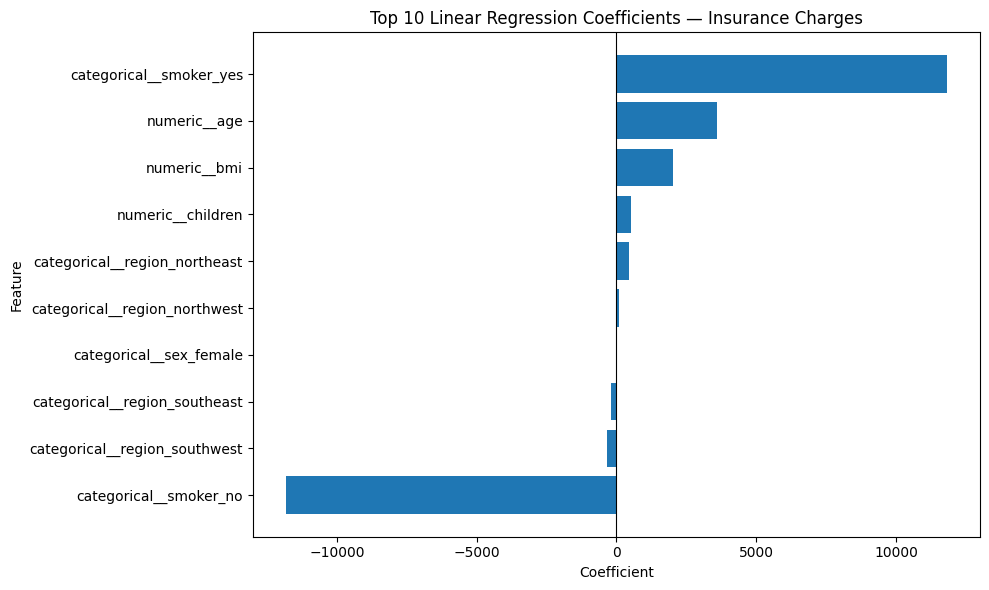

In [8]:
# Part A: Coefficient analysis

preprocessor = linear_model.named_steps["preprocessor"]
regressor = linear_model.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()
coefficients = regressor.coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs_Coefficient", ascending=False)

display(coef_df.drop(columns="Abs_Coefficient").round(2))

# Plot the 10 features with the largest absolute coefficients
top_coef = coef_df.head(10).sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(top_coef["Feature"], top_coef["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Linear Regression Coefficients — Insurance Charges")
plt.tight_layout()
plt.show()

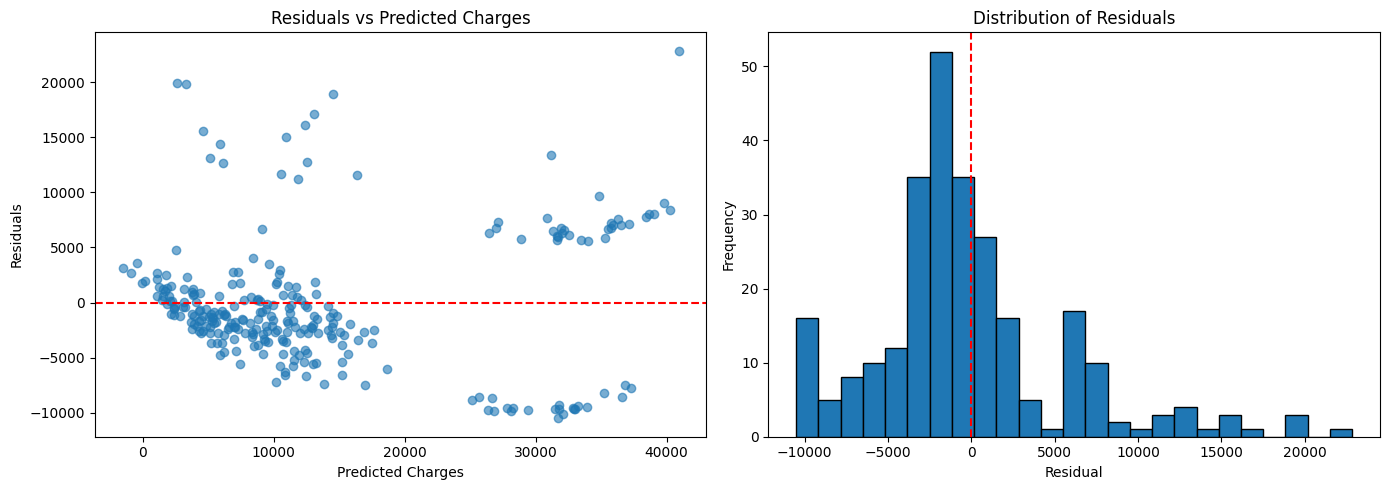

Mean residual: -219.24
Residual standard deviation: 5802.97
Largest overprediction: 10512.58
Largest underprediction: 22850.14


In [9]:
# Part A: Residual analysis

residuals = y_val - linear_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals against predicted values
axes[0].scatter(linear_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Charges")

# Distribution of residuals
axes[1].hist(residuals, bins=25, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Residuals")

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))
print("Largest overprediction:", round(-residuals.min(), 2))
print("Largest underprediction:", round(residuals.max(), 2))

In [10]:
# Save the fitted insurance model pipeline

insurance_model_path = MODELS / "insurance_charges.joblib"

joblib.dump(linear_model, insurance_model_path)

print("Saved:", insurance_model_path)
print("File size:", round(insurance_model_path.stat().st_size / 1024, 2), "KB")

Saved: /content/UTP-MACHINE-LEARNING/models/insurance_charges.joblib
File size: 4.4 KB


### Part A — Conclusion

Linear Regression achieved a validation MAE of 4,181.19, RMSE of 5,796.29, and R² of 0.784. Ridge Regression produced slightly weaker results, with a MAE of 4,186.91, RMSE of 5,798.30, and R² of 0.783. Therefore, Linear Regression performed marginally better on this validation split.

The coefficient analysis identified smoking status as the strongest predictor in the fitted model, followed by age and BMI. The residual plots showed structured patterns and a positive tail, indicating that prediction errors were not entirely random and that the model struggled with some high-charge cases.

Overall, Linear Regression provides a useful baseline, but more flexible models or nonlinear feature relationships may improve predictions. The observed associations should not be interpreted as causal effects.

In [ ]:
# Part B1: Daily bike rental regression

bike_day = datasets["bike_day"].copy()

# Sort by date to preserve chronological order
bike_day["dteday"] = pd.to_datetime(bike_day["dteday"])
bike_day = bike_day.sort_values("dteday").reset_index(drop=True)

# Target: total daily rentals
target = "cnt"

# Exclude target, date, and leakage columns
exclude_columns = [
    "cnt",
    "casual",
    "registered",
    "dteday"
]

feature_columns = [
    col for col in bike_day.columns
    if col not in exclude_columns
]

X_day = bike_day[feature_columns]
y_day = bike_day[target]

# Chronological 80/20 split — no shuffling
split_index = int(len(bike_day) * 0.80)

X_day_train = X_day.iloc[:split_index]
X_day_val = X_day.iloc[split_index:]
y_day_train = y_day.iloc[:split_index]
y_day_val = y_day.iloc[split_index:]

print("Daily dataset shape:", bike_day.shape)
print("Training rows:", len(X_day_train))
print("Validation rows:", len(X_day_val))
print("Training date range:",
      bike_day["dteday"].iloc[0].date(), "to",
      bike_day["dteday"].iloc[split_index - 1].date())
print("Validation date range:",
      bike_day["dteday"].iloc[split_index].date(), "to",
      bike_day["dteday"].iloc[-1].date())
print("Features used:", feature_columns)

In [11]:
# Part B1: Daily bike rental regression

bike_day = datasets["bike_day"].copy()

# Convert date column and sort chronologically
bike_day["dteday"] = pd.to_datetime(bike_day["dteday"])
bike_day = bike_day.sort_values("dteday").reset_index(drop=True)

# Define target and exclude leakage columns
target = "cnt"
exclude_columns = ["cnt", "casual", "registered", "dteday"]
feature_columns = [
    col for col in bike_day.columns
    if col not in exclude_columns
]

X_day = bike_day[feature_columns]
y_day = bike_day[target]

# Chronological 80/20 split (no shuffling)
split_index = int(len(bike_day) * 0.80)

X_day_train = X_day.iloc[:split_index]
X_day_val = X_day.iloc[split_index:]
y_day_train = y_day.iloc[:split_index]
y_day_val = y_day.iloc[split_index:]

print("Daily dataset shape:", bike_day.shape)
print("Training rows:", len(X_day_train))
print("Validation rows:", len(X_day_val))

print(
    "Training date range:",
    bike_day["dteday"].iloc[0].date(), "to",
    bike_day["dteday"].iloc[split_index - 1].date()
)

print(
    "Validation date range:",
    bike_day["dteday"].iloc[split_index].date(), "to",
    bike_day["dteday"].iloc[-1].date()
)

print("Features used:", feature_columns)

Daily dataset shape: (731, 16)
Training rows: 584
Validation rows: 147
Training date range: 2011-01-01 to 2012-08-06
Validation date range: 2012-08-07 to 2012-12-31
Features used: ['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [12]:
# Train Random Forest Regressor on daily data

daily_model = Pipeline([
    ("preprocessor", make_preprocessor(X_day_train)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

daily_model.fit(X_day_train, y_day_train)

# Predict on validation data
daily_pred = daily_model.predict(X_day_val)

# Evaluate performance
daily_results = regression_metrics(y_day_val, daily_pred)

print("Daily bike rental results")
display(
    pd.DataFrame(
        [daily_results],
        index=["Random Forest"]
    ).round(3)
)

Daily bike rental results


,MAE,RMSE,R2
Random Forest,836.318,1184.002,0.601


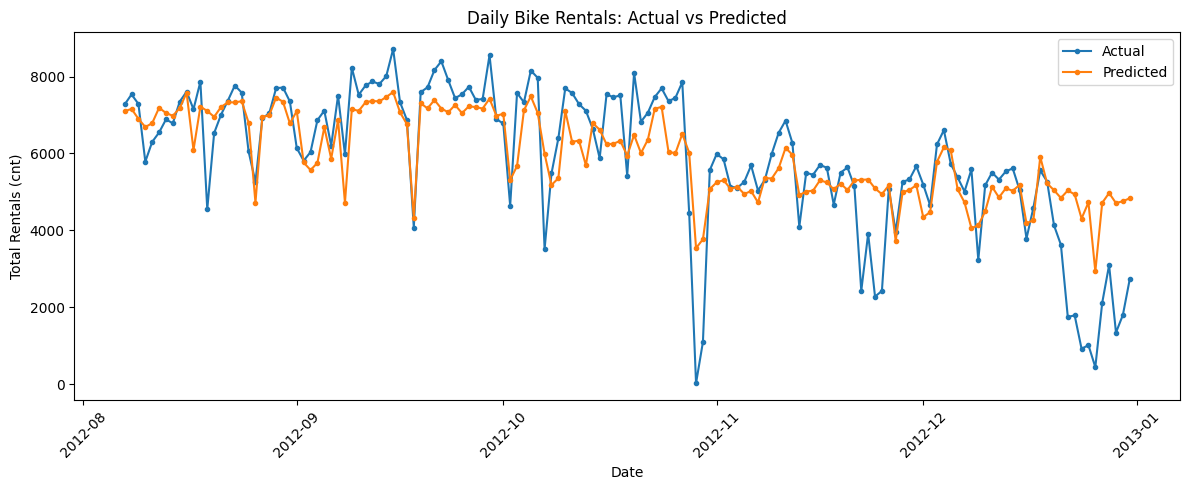

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    bike_day["dteday"].iloc[split_index:],
    y_day_val.to_numpy(),
    label="Actual",
    marker=".",
    linewidth=1.5
)

plt.plot(
    bike_day["dteday"].iloc[split_index:],
    daily_pred,
    label="Predicted",
    marker=".",
    linewidth=1.5
)

plt.xlabel("Date")
plt.ylabel("Total Rentals (cnt)")
plt.title("Daily Bike Rentals: Actual vs Predicted")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### B1. Daily Bike Rental Model Analysis

The Random Forest model follows the general trend of actual daily bike rentals reasonably well during the validation period. However, its predictions do not fully capture the sharp drops in rental demand, particularly during late October, November, and January.

The model consistently overpredicts rentals during low-demand periods. Its predictions are also smoother than the actual values, indicating difficulty capturing sudden fluctuations and extreme changes in demand.

Overall, the model captures the broad rental pattern but struggles with sharp declines and highly variable demand. This may be partly due to the limited ability of the selected features to represent unusual events or sudden changes in rental behaviour.

In [14]:
# Part B2: Hourly bike rental regression

bike_hour = datasets["bike_hour"].copy()

# Convert date and sort chronologically
bike_hour["dteday"] = pd.to_datetime(bike_hour["dteday"])
bike_hour = bike_hour.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

# Define target and exclude leakage columns
target = "cnt"
exclude_columns = ["cnt", "casual", "registered", "dteday"]

feature_columns_hour = [
    col for col in bike_hour.columns
    if col not in exclude_columns
]

X_hour = bike_hour[feature_columns_hour]
y_hour = bike_hour[target]

# Chronological 80/20 split
split_index_hour = int(len(bike_hour) * 0.80)

X_hour_train = X_hour.iloc[:split_index_hour]
X_hour_val = X_hour.iloc[split_index_hour:]
y_hour_train = y_hour.iloc[:split_index_hour]
y_hour_val = y_hour.iloc[split_index_hour:]

print("Hourly dataset shape:", bike_hour.shape)
print("Training rows:", len(X_hour_train))
print("Validation rows:", len(X_hour_val))

print(
    "Training date range:",
    bike_hour["dteday"].iloc[0].date(), "to",
    bike_hour["dteday"].iloc[split_index_hour - 1].date()
)

print(
    "Validation date range:",
    bike_hour["dteday"].iloc[split_index_hour].date(), "to",
    bike_hour["dteday"].iloc[-1].date()
)

print("Features used:", feature_columns_hour)

Hourly dataset shape: (17379, 17)
Training rows: 13903
Validation rows: 3476
Training date range: 2011-01-01 to 2012-08-07
Validation date range: 2012-08-07 to 2012-12-31
Features used: ['instant', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [15]:
# Train Random Forest Regressor on hourly data

hourly_model = Pipeline([
    ("preprocessor", make_preprocessor(X_hour_train)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

hourly_model.fit(X_hour_train, y_hour_train)

# Predict on validation data
hourly_pred = hourly_model.predict(X_hour_val)

# Evaluate performance
hourly_results = regression_metrics(y_hour_val, hourly_pred)

print("Hourly bike rental results")
display(
    pd.DataFrame(
        [hourly_results],
        index=["Random Forest"]
    ).round(3)
)

Hourly bike rental results


,MAE,RMSE,R2
Random Forest,48.836,80.044,0.868


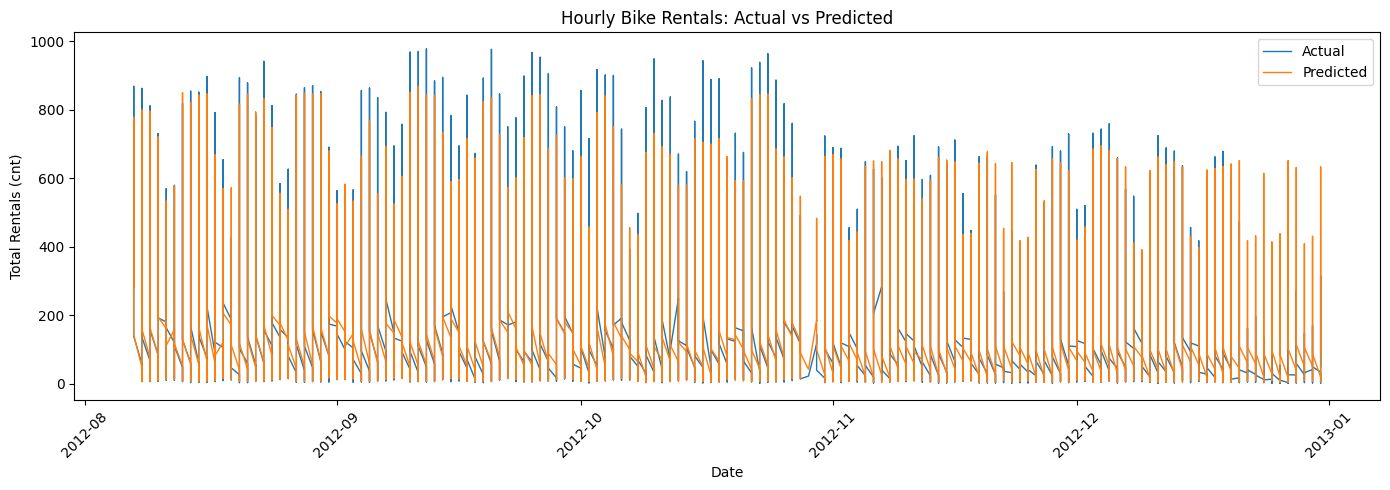

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    bike_hour["dteday"].iloc[split_index_hour:],
    y_hour_val.to_numpy(),
    label="Actual",
    linewidth=1
)

plt.plot(
    bike_hour["dteday"].iloc[split_index_hour:],
    hourly_pred,
    label="Predicted",
    linewidth=1
)

plt.xlabel("Date")
plt.ylabel("Total Rentals (cnt)")
plt.title("Hourly Bike Rentals: Actual vs Predicted")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### B2. Hourly Bike Rental Model Analysis

The Random Forest model captures recurring daily rental patterns reasonably well, including the peaks and troughs in hourly bike demand throughout the validation period.

However, the model tends to underpredict during high-demand periods, where actual rental counts exceed the predicted values. It also slightly overpredicts during low-demand periods, with predictions remaining above some of the actual minimum values.

Overall, the model identifies general hourly demand patterns but has difficulty capturing extreme peaks and low-demand observations. This suggests that the model's predictions are less accurate during periods of unusually high or low rental activity.

### B3. Part B Conclusion

Random Forest Regression was applied to both daily and hourly bike rental datasets using chronological 80/20 training and validation splits. The target variable was total rentals (`cnt`), while `casual` and `registered` were excluded to prevent target leakage.

For daily rentals, the model followed the overall trend but struggled with sharp declines and low-demand periods. For hourly rentals, it captured recurring demand cycles but tended to underpredict high-demand peaks and overpredict some low-demand observations.

These findings show that Random Forest can capture general rental patterns, although prediction errors remain around extreme demand levels. MAE, RMSE, and R² should be used alongside the plots to compare the models quantitatively. Because the daily and hourly datasets have different observation frequencies, their error magnitudes should be interpreted in context rather than compared directly without considering their scales.


In [17]:
# Save daily and hourly bike rental models

joblib.dump(
    daily_model,
    MODELS / "bike_daily_rentals.joblib"
)

joblib.dump(
    hourly_model,
    MODELS / "bike_hourly_rentals.joblib"
)

print("Saved models:")
print(MODELS / "bike_daily_rentals.joblib")
print(MODELS / "bike_hourly_rentals.joblib")

Saved models:
/content/UTP-MACHINE-LEARNING/models/bike_daily_rentals.joblib
/content/UTP-MACHINE-LEARNING/models/bike_hourly_rentals.joblib


In [18]:
print("Saved model files:")
for path in sorted(MODELS.glob("bike_*rentals.joblib")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Saved model files:
bike_daily_rentals.joblib: 10,688,067 bytes
bike_hourly_rentals.joblib: 237,299,315 bytes


## Part C — Classification

### Objective
Build classification models to predict categorical outcomes and evaluate their performance using appropriate classification metrics.

### Part C1: Titanic Survival Prediction
- Target variable: `Survived`
- Models: Logistic Regression and Random Forest Classifier
- Compare accuracy and ROC AUC.
- Evaluate precision and recall at probability thresholds of 0.3, 0.5, and 0.7.

### Part C2: Breast Cancer Classification
- Target variable: `diagnosis`
- Models: Logistic Regression
- Examine predicted probability distributions.
- Compare classification thresholds and evaluate the confusion matrix, precision, recall, ROC AUC, and average precision.
- Plot ROC and precision-recall curves.

Preprocessing is performed within scikit-learn pipelines to avoid data leakage between training and validation data.

In [19]:
# Part C1: Titanic survival classification

titanic_df = datasets["titanic"].copy()

# Select the seven input features
titanic_features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X_titanic = titanic_df[titanic_features]
y_titanic = titanic_df["Survived"]

# Stratified 80/20 train-validation split
X_titanic_train, X_titanic_val, y_titanic_train, y_titanic_val = (
    train_test_split(
        X_titanic,
        y_titanic,
        test_size=0.20,
        random_state=42,
        stratify=y_titanic
    )
)

print("Dataset shape:", titanic_df.shape)
print("Training rows:", len(X_titanic_train))
print("Validation rows:", len(X_titanic_val))

print("\nTraining target distribution:")
print(y_titanic_train.value_counts())

print("\nValidation target distribution:")
print(y_titanic_val.value_counts())

print("\nFeatures used:", titanic_features)

Dataset shape: (891, 12)
Training rows: 712
Validation rows: 179

Training target distribution:
Survived
0    439
1    273
Name: count, dtype: int64

Validation target distribution:
Survived
0    110
1     69
Name: count, dtype: int64

Features used: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [20]:
# Train Logistic Regression and Random Forest Classifier

# Logistic Regression pipeline
titanic_logistic = Pipeline([
    ("preprocessor", make_preprocessor(X_titanic_train)),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Random Forest pipeline
titanic_rf = Pipeline([
    ("preprocessor", make_preprocessor(X_titanic_train)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit models
titanic_logistic.fit(X_titanic_train, y_titanic_train)
titanic_rf.fit(X_titanic_train, y_titanic_train)

# Generate predictions and survival probabilities
logistic_pred = titanic_logistic.predict(X_titanic_val)
logistic_prob = titanic_logistic.predict_proba(X_titanic_val)[:, 1]

rf_pred = titanic_rf.predict(X_titanic_val)
rf_prob = titanic_rf.predict_proba(X_titanic_val)[:, 1]

print("Both Titanic classification models trained successfully.")

Both Titanic classification models trained successfully.


In [21]:
# Evaluate accuracy and ROC AUC

titanic_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_titanic_val, logistic_pred),
        accuracy_score(y_titanic_val, rf_pred)
    ],
    "ROC AUC": [
        roc_auc_score(y_titanic_val, logistic_prob),
        roc_auc_score(y_titanic_val, rf_prob)
    ]
}).set_index("Model")

display(titanic_results.round(3))

,Accuracy,ROC AUC
Model,,
Logistic Regression,0.804,0.844
Random Forest,0.816,0.830


In [22]:
# Compare thresholds for Titanic survival prediction

threshold_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_prob),
    ("Random Forest", rf_prob)
]:
    for threshold in [0.3, 0.5, 0.7]:
        predictions = (probabilities >= threshold).astype(int)

        threshold_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_titanic_val, predictions),
            "Precision": precision_score(
                y_titanic_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_titanic_val, predictions, zero_division=0
            )
        })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

,Model,Threshold,Accuracy,Precision,Recall
0,Logistic Regression,0.3,0.760,0.655,0.797
1,Logistic Regression,0.5,0.804,0.793,0.667
2,Logistic Regression,0.7,0.788,0.897,0.507
3,Random Forest,0.3,0.782,0.683,0.812
4,Random Forest,0.5,0.816,0.800,0.696
5,Random Forest,0.7,0.793,0.833,0.580


### C1. Titanic Classification Results

Logistic Regression and Random Forest were evaluated using accuracy and ROC AUC on the same validation set. Random Forest achieved a higher accuracy of 0.816, while Logistic Regression achieved a higher ROC AUC of 0.844. This indicates that Random Forest performed slightly better at the default classification threshold, whereas Logistic Regression ranked survivors and non-survivors more effectively across different thresholds.

Threshold analysis showed a trade-off between precision and recall. At a threshold of 0.3, both models achieved higher recall but lower precision. At a threshold of 0.7, precision increased while recall decreased. Therefore, the threshold should be selected according to the relative importance of identifying more survivors versus reducing false-positive predictions.

Overall, neither model dominated across all metrics. Random Forest was stronger in validation accuracy, while Logistic Regression was stronger in ROC AUC.


In [23]:
# Part C2: Breast cancer classification

breast_df = datasets["breast_cancer"].copy()

# Remove identifier and empty column
breast_df = breast_df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Separate features and target
X_breast = breast_df.drop(columns=["diagnosis"])
y_breast = (breast_df["diagnosis"] == "M").astype(int)

# Stratified train-validation split
X_breast_train, X_breast_val, y_breast_train, y_breast_val = (
    train_test_split(
        X_breast,
        y_breast,
        test_size=0.20,
        random_state=42,
        stratify=y_breast
    )
)

print("Dataset shape after cleaning:", breast_df.shape)
print("Training rows:", len(X_breast_train))
print("Validation rows:", len(X_breast_val))
print("\nTarget distribution (0 = benign, 1 = malignant):")
print(y_breast.value_counts().sort_index())
print("\nTraining features:", X_breast_train.shape[1])

Dataset shape after cleaning: (569, 31)
Training rows: 455
Validation rows: 114

Target distribution (0 = benign, 1 = malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64

Training features: 30


In [27]:
# Train Logistic Regression for breast cancer classification

breast_model = Pipeline([
    ("preprocessor", make_preprocessor(X_breast_train)),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

breast_model.fit(X_breast_train, y_breast_train)

# Predicted probabilities and default predictions
breast_prob = breast_model.predict_proba(X_breast_val)[:, 1]
breast_pred_05 = (breast_prob >= 0.5).astype(int)

print("Breast cancer Logistic Regression trained successfully.")

Breast cancer Logistic Regression trained successfully.


In [28]:
# Evaluate the default probability threshold

print("Accuracy:", round(
    accuracy_score(y_breast_val, breast_pred_05), 3
))
print("ROC AUC:", round(
    roc_auc_score(y_breast_val, breast_prob), 3
))
print("Average Precision:", round(
    average_precision_score(y_breast_val, breast_prob), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_breast_val, breast_pred_05))

print("\nClassification Report:")
print(classification_report(
    y_breast_val,
    breast_pred_05,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Accuracy: 0.965
ROC AUC: 0.996
Average Precision: 0.994

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



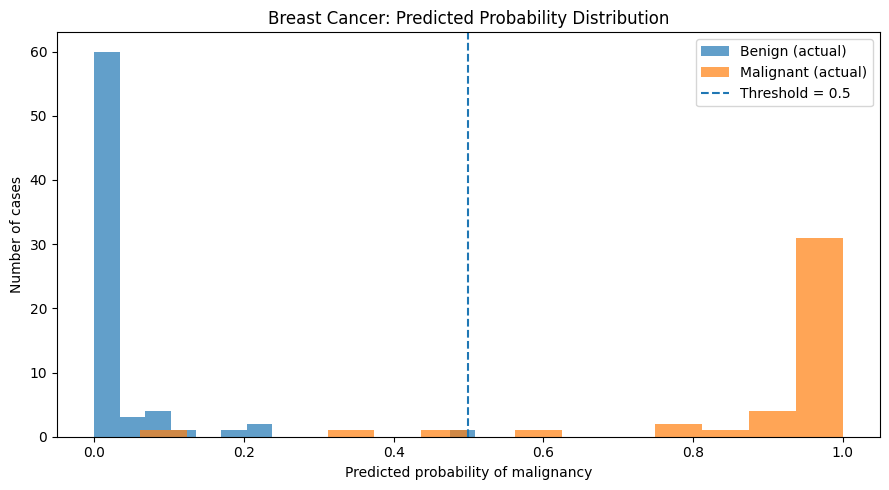

In [29]:
plt.figure(figsize=(9, 5))

plt.hist(
    breast_prob[y_breast_val.to_numpy() == 0],
    bins=15,
    alpha=0.7,
    label="Benign (actual)"
)

plt.hist(
    breast_prob[y_breast_val.to_numpy() == 1],
    bins=15,
    alpha=0.7,
    label="Malignant (actual)"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Predicted probability of malignancy")
plt.ylabel("Number of cases")
plt.title("Breast Cancer: Predicted Probability Distribution")
plt.legend()
plt.tight_layout()
plt.show()

### C2.1. Predicted Probability Analysis

The predicted probability histogram shows strong separation between benign and malignant cases. Most benign cases receive probabilities close to 0, while most malignant cases receive probabilities close to 1.

The default threshold of 0.5 appears to separate the two classes effectively, although a small number of cases may fall on the wrong side of the threshold. The confusion matrix and classification report are used to verify the number of false positives and false negatives.

Overall, the probability distribution suggests that Logistic Regression distinguishes the two classes effectively on the validation set. However, validation results alone do not establish how the model would perform on unseen clinical data.


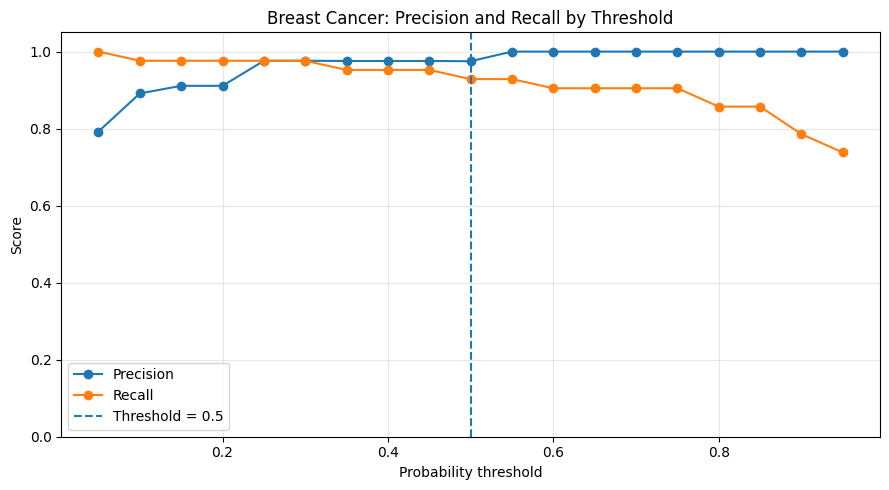

In [30]:
# Precision and recall across probability thresholds

thresholds = np.arange(0.05, 1.00, 0.05)
precision_values = []
recall_values = []

for threshold in thresholds:
    predictions = (breast_prob >= threshold).astype(int)

    precision_values.append(
        precision_score(y_breast_val, predictions, zero_division=0)
    )
    recall_values.append(
        recall_score(y_breast_val, predictions, zero_division=0)
    )

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")
plt.axvline(0.5, linestyle="--", label="Threshold = 0.5")

plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Breast Cancer: Precision and Recall by Threshold")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

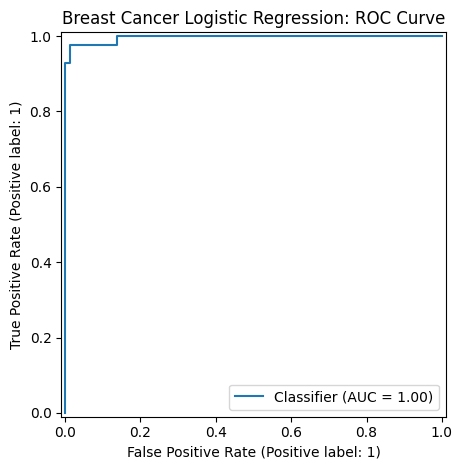

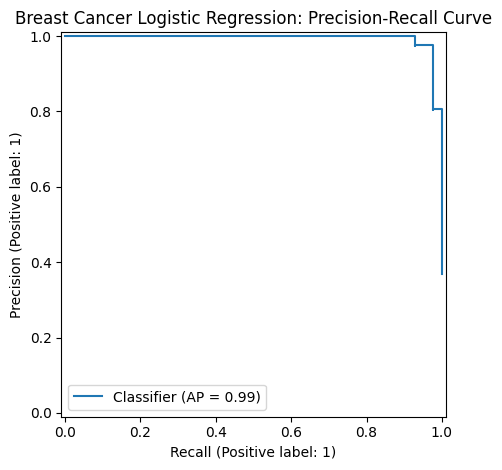

In [31]:
# ROC curve
RocCurveDisplay.from_predictions(y_breast_val, breast_prob)
plt.title("Breast Cancer Logistic Regression: ROC Curve")
plt.tight_layout()
plt.show()

# Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_breast_val, breast_prob)
plt.title("Breast Cancer Logistic Regression: Precision-Recall Curve")
plt.tight_layout()
plt.show()

### C2.2. Threshold and Curve Analysis

Precision and recall vary with the classification threshold. Lower thresholds generally increase recall by identifying more malignant cases, but may also classify more benign cases as malignant. Higher thresholds generally increase selectivity but risk missing additional malignant cases.

The ROC curve evaluates the model's ability to distinguish between benign and malignant cases across thresholds, while the precision-recall curve focuses on performance when identifying malignant cases. ROC AUC and average precision provide numerical summaries of these aspects of performance.

The probability histogram suggests strong class separation, but the final assessment should consider the confusion matrix, classification report, ROC AUC, average precision, and threshold analysis together.




### C2.3. Breast Cancer Classification Results

The Logistic Regression model demonstrated strong separation between benign and malignant cases in the predicted probability histogram. Most benign cases received low predicted probabilities of malignancy, while most malignant cases received high probabilities.

The precision-recall analysis showed that precision generally remained high as the classification threshold increased, while recall decreased because more cases were classified as negative. At stricter thresholds, precision reached 1.00, indicating no false-positive predictions at those evaluated thresholds, although some malignant cases may have been missed.

The ROC curve reported an AUC of 1.00, and the precision-recall curve reported an average precision of approximately 0.99. These results indicate excellent discrimination on the validation set. However, the findings should be interpreted cautiously because performance on a single validation split may not generalise to independent clinical data.


## Part D — Hyperparameter Tuning

### Objective
Improve Titanic survival classification by tuning Logistic Regression hyperparameters using cross-validation.

### Methodology
- Split the Titanic dataset into training and test sets.
- Use a stratified 80/20 split to preserve class proportions.
- Tune the regularisation parameter `C` and `class_weight` using `GridSearchCV`.
- Use five-fold stratified cross-validation with ROC AUC as the selection metric.
- Evaluate the selected model once on the held-out test set.

The test set is reserved for final evaluation and is not used during hyperparameter selection.


In [32]:
# Part D: Prepare Titanic data for hyperparameter tuning

X_titanic_all = titanic_df[titanic_features]
y_titanic_all = titanic_df["Survived"]

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_titanic_all,
    y_titanic_all,
    test_size=0.20,
    random_state=42,
    stratify=y_titanic_all
)

print("Training rows:", len(X_train_d))
print("Test rows:", len(X_test_d))

print("\nTraining class distribution:")
print(y_train_d.value_counts())

print("\nTest class distribution:")
print(y_test_d.value_counts())

Training rows: 712
Test rows: 179

Training class distribution:
Survived
0    439
1    273
Name: count, dtype: int64

Test class distribution:
Survived
0    110
1     69
Name: count, dtype: int64


In [33]:
# Define pipeline
titanic_tuning_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(X_train_d)),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Hyperparameter grid
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

# Stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=titanic_tuning_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train_d, y_train_d)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation ROC AUC:")
print(round(grid_search.best_score_, 3))

Best parameters:
{'model__C': 1, 'model__class_weight': None}

Best mean cross-validation ROC AUC:
0.855


In [34]:
# Final evaluation on the held-out test set

best_titanic_model = grid_search.best_estimator_

test_prob = best_titanic_model.predict_proba(X_test_d)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

print("Test Accuracy:", round(
    accuracy_score(y_test_d, test_pred), 3
))
print("Test ROC AUC:", round(
    roc_auc_score(y_test_d, test_prob), 3
))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test_d, test_pred))

print("\nTest Classification Report:")
print(classification_report(
    y_test_d,
    test_pred,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))

Test Accuracy: 0.804
Test ROC AUC: 0.844

Test Confusion Matrix:
[[98 12]
 [23 46]]

Test Classification Report:
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



### D1. Hyperparameter Tuning and Test Evaluation

Logistic Regression was tuned using GridSearchCV with five-fold stratified cross-validation. The search evaluated different values of the regularisation parameter `C` and two class-weight settings, using ROC AUC to select the best configuration.

On the held-out test set of 179 passengers, the selected model achieved an accuracy of 0.804 and a ROC AUC of 0.844. The confusion matrix contained 98 true negatives, 12 false positives, 23 false negatives, and 46 true positives.

The model correctly classified most passengers who did not survive, with a recall of approximately 0.89 for that class. Survivor recall was approximately 0.67, indicating that some actual survivors were incorrectly classified as non-survivors.

Overall, the test results indicate reasonable predictive performance, although the model identifies non-survivors more effectively than survivors at the default threshold. The held-out test results provide an estimate of generalisation performance on data not used during model fitting or hyperparameter selection.


In [35]:
print("Best parameters:", grid_search.best_params_)
print("Best CV ROC AUC:", round(grid_search.best_score_, 3))

Best parameters: {'model__C': 1, 'model__class_weight': None}
Best CV ROC AUC: 0.855


### D2. Hyperparameter Selection

GridSearchCV selected `C = 1` and `class_weight = None` as the best hyperparameter configuration, achieving a mean cross-validation ROC AUC of 0.855.

The selected model achieved a test ROC AUC of 0.844 and test accuracy of 0.804. The small difference between cross-validation and test ROC AUC suggests broadly consistent ranking performance on the two evaluation settings.

The selected configuration was chosen using cross-validation, while the held-out test set was reserved for final evaluation. This separation helps provide a more reliable estimate of performance on unseen data.


## Part E — Model Persistence and Reloading

### Objective
Save trained models and verify that they can be reloaded for future predictions.

### Deliverables
- `models/titanic_survival.joblib`
- `models/titanic_survival_card.json`
- `models/insurance_charges.joblib`

The Titanic model is the best estimator selected through cross-validation in Part D. The insurance model is the fitted Linear Regression pipeline from Part A.

The saved models are reloaded and tested on example inputs to verify that their prediction pipelines remain functional.

In [36]:
# Save the best Titanic model
titanic_model_path = MODELS / "titanic_survival.joblib"
joblib.dump(best_titanic_model, titanic_model_path)

# Create a model information card
titanic_model_card = {
    "model_name": "Titanic Survival Prediction",
    "algorithm": "Logistic Regression",
    "dataset": "Titanic",
    "target": "Survived",
    "features": titanic_features,
    "best_parameters": grid_search.best_params_,
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42,
        "scoring": "roc_auc",
        "best_mean_roc_auc": float(grid_search.best_score_)
    },
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test_d, test_pred)),
        "roc_auc": float(roc_auc_score(y_test_d, test_prob))
    },
    "decision_threshold": 0.5
}

card_path = MODELS / "titanic_survival_card.json"

with open(card_path, "w") as f:
    json.dump(titanic_model_card, f, indent=4)

print("Saved:")
print(titanic_model_path)
print(card_path)

Saved:
/content/UTP-MACHINE-LEARNING/models/titanic_survival.joblib
/content/UTP-MACHINE-LEARNING/models/titanic_survival_card.json


In [37]:
required_files = [
    MODELS / "insurance_charges.joblib",
    MODELS / "titanic_survival.joblib",
    MODELS / "titanic_survival_card.json"
]

for path in required_files:
    if path.exists():
        print(f"OK: {path.name} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {path.name}")

OK: insurance_charges.joblib (4,506 bytes)
OK: titanic_survival.joblib (4,554 bytes)
OK: titanic_survival_card.json (738 bytes)


In [38]:
# Reload saved models
loaded_titanic_model = joblib.load(
    MODELS / "titanic_survival.joblib"
)

loaded_insurance_model = joblib.load(
    MODELS / "insurance_charges.joblib"
)

# Example Titanic passenger
example_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "female",
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S"
}])

# Predict survival
passenger_probability = loaded_titanic_model.predict_proba(
    example_passenger
)[0, 1]

passenger_prediction = loaded_titanic_model.predict(
    example_passenger
)[0]

print("Titanic example prediction")
print("Predicted class:", "Survived" if passenger_prediction == 1 else "Did not survive")
print("Probability of survival:", round(passenger_probability, 3))

Titanic example prediction
Predicted class: Survived
Probability of survival: 0.603


In [39]:
# Two illustrative insurance customer profiles
example_customers = pd.DataFrame([
    {
        "age": 25,
        "sex": "female",
        "bmi": 22.5,
        "children": 0,
        "smoker": "no",
        "region": "northeast"
    },
    {
        "age": 45,
        "sex": "male",
        "bmi": 32.0,
        "children": 2,
        "smoker": "yes",
        "region": "southeast"
    }
])

# Predict insurance charges using the reloaded model
predicted_charges = loaded_insurance_model.predict(
    example_customers
)

insurance_predictions = example_customers.copy()
insurance_predictions["predicted_charges"] = predicted_charges

display(insurance_predictions.round(2))

,age,sex,bmi,children,smoker,region,predicted_charges
0,25,female,22.5,0,no,northeast,2077.76
1,45,male,32.0,2,yes,southeast,34244.88


In [40]:
with open(MODELS / "titanic_survival_card.json", "r") as f:
    loaded_card = json.load(f)

print(json.dumps(loaded_card, indent=2))

{
  "model_name": "Titanic Survival Prediction",
  "algorithm": "Logistic Regression",
  "dataset": "Titanic",
  "target": "Survived",
  "features": [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
  ],
  "best_parameters": {
    "model__C": 1,
    "model__class_weight": null
  },
  "cross_validation": {
    "method": "StratifiedKFold",
    "n_splits": 5,
    "shuffle": true,
    "random_state": 42,
    "scoring": "roc_auc",
    "best_mean_roc_auc": 0.8551333211952334
  },
  "test_metrics": {
    "accuracy": 0.8044692737430168,
    "roc_auc": 0.8437417654808959
  },
  "decision_threshold": 0.5
}


## Try It — Heart Failure Classification

### Objective
Build a classification pipeline to predict the presence of heart disease using the heart failure dataset.

### Methodology
- Target variable: `HeartDisease`
- Identify numerical and categorical features using data types.
- Split the dataset into training and validation sets using stratification.
- Apply imputation, scaling, and one-hot encoding through the shared preprocessing pipeline.
- Train a Logistic Regression classifier.
- Evaluate accuracy, ROC AUC, and the confusion matrix at a threshold of 0.5.

This exercise applies the preprocessing and evaluation workflow developed earlier in the notebook to a new classification dataset.


In [41]:
# Heart failure classification

heart_df = datasets["heart_failure"].copy()

target = "HeartDisease"
X_heart = heart_df.drop(columns=[target])
y_heart = heart_df[target]

# Stratified train-validation split
X_heart_train, X_heart_val, y_heart_train, y_heart_val = (
    train_test_split(
        X_heart,
        y_heart,
        test_size=0.20,
        random_state=42,
        stratify=y_heart
    )
)

numeric_features_heart = X_heart_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_heart = X_heart_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Dataset shape:", heart_df.shape)
print("Training rows:", len(X_heart_train))
print("Validation rows:", len(X_heart_val))
print("Numerical features:", numeric_features_heart)
print("Categorical features:", categorical_features_heart)
print("\nTarget distribution:")
print(y_heart.value_counts().sort_index())

Dataset shape: (918, 12)
Training rows: 734
Validation rows: 184
Numerical features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Target distribution:
HeartDisease
0    410
1    508
Name: count, dtype: int64


In [42]:
# Train Logistic Regression
heart_model = Pipeline([
    ("preprocessor", make_preprocessor(X_heart_train)),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

heart_model.fit(X_heart_train, y_heart_train)

# Evaluate at threshold 0.5
heart_prob = heart_model.predict_proba(X_heart_val)[:, 1]
heart_pred = (heart_prob >= 0.5).astype(int)

print("Accuracy:", round(
    accuracy_score(y_heart_val, heart_pred), 3
))
print("ROC AUC:", round(
    roc_auc_score(y_heart_val, heart_prob), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_heart_val, heart_pred))

print("\nClassification Report:")
print(classification_report(
    y_heart_val,
    heart_pred,
    target_names=["No Heart Disease", "Heart Disease"],
    zero_division=0
))

Accuracy: 0.886
ROC AUC: 0.93

Confusion Matrix:
[[68 14]
 [ 7 95]]

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.91      0.83      0.87        82
   Heart Disease       0.87      0.93      0.90       102

        accuracy                           0.89       184
       macro avg       0.89      0.88      0.88       184
    weighted avg       0.89      0.89      0.89       184



### Heart Failure Classification Results

Logistic Regression was applied to the heart failure dataset using a stratified training-validation split. Numerical and categorical features were processed through the shared preprocessing pipeline.

Model performance was evaluated using accuracy, ROC AUC, the confusion matrix, and the classification report at a probability threshold of 0.5. Accuracy measures the proportion of correct predictions, while ROC AUC evaluates the model's ability to rank positive cases above negative cases across thresholds.

The confusion matrix and class-specific recall help identify errors in detecting heart disease. These results demonstrate the application of the classification workflow to a second dataset. The model is intended for educational evaluation and should not be used for clinical diagnosis.


### Interpretation of Results

The Logistic Regression classifier achieved an accuracy of **88.6%** and a ROC AUC of **0.93**, indicating good classification performance on the validation set.

For the **Heart Disease** class, precision was 0.87 and recall was 0.93. This means that 87% of cases predicted as having heart disease were positive in the validation labels, while the model identified 93% of all actual positive cases. The confusion matrix shows that 95 positive cases were correctly identified, while 7 positive cases were missed. Another 14 cases without heart disease were incorrectly classified as positive.

The recall of 0.93 is encouraging for identifying positive cases, but the false negatives and false positives remain important. Since this is a classroom experiment, the results should not be interpreted as evidence of clinical suitability or used for medical decisions.


## Overall Conclusion

This lab explored supervised learning through regression and classification tasks using multiple datasets.

- **Regression:** Linear Regression and Ridge Regression were compared for insurance charge prediction. Random Forest Regression was applied to daily and hourly bike rental prediction.
- **Classification:** Logistic Regression and Random Forest were evaluated for Titanic survival prediction, while Logistic Regression was used for breast cancer and heart disease classification.
- **Hyperparameter tuning:** GridSearchCV with stratified five-fold cross-validation was used to optimise the Titanic Logistic Regression model based on ROC AUC.
- **Model deployment preparation:** Trained models were saved using Joblib, and a JSON model card was created to document the Titanic model's configuration and evaluation results.

The experiments demonstrated the importance of appropriate preprocessing, data splitting, model evaluation, and threshold selection. Results also showed that model performance varies by dataset and task. Validation metrics provide useful evidence of model performance, but they do not guarantee equivalent performance on unseen real-world data.


In [43]:
# Check the repository and saved model artifacts

print("Repository exists:", REPO.exists())
print("Experiments folder exists:", EXPERIMENTS.exists())
print("Models folder exists:", MODELS.exists())

print("\nExperiment files:")
for file in sorted(EXPERIMENTS.glob("*")):
    print(file.name, f"({file.stat().st_size:,} bytes)")

print("\nModel files:")
for file in sorted(MODELS.glob("*")):
    if file.is_file():
        print(file.name, f"({file.stat().st_size:,} bytes)")

Repository exists: True
Experiments folder exists: True
Models folder exists: True

Experiment files:
Lab01_feature_engineering.ipynb (214,164 bytes)
lab03_model_families.ipynb (764,690 bytes)

Model files:
bike_daily_rentals.joblib (10,688,067 bytes)
bike_hourly_rentals.joblib (237,299,315 bytes)
breast_cancer_svm.joblib (16,797 bytes)
insurance_charges.joblib (4,506 bytes)
titanic_survival.joblib (4,554 bytes)
titanic_survival_card.json (738 bytes)


In [45]:
from pathlib import Path

for path in Path("/content").rglob("Lab02_supervised_learning.ipynb"):
    print(path)

In [ ]:
from pathlib import Path
import shutil

source_notebook = Path("/content/REPLACE_WITH_THE_PATH_FROM_STEP_12_1")
destination_notebook = EXPERIMENTS / "Lab02_supervised_learning.ipynb"

shutil.copy2(source_notebook, destination_notebook)

print("Notebook saved:", destination_notebook.exists())
print("File size:", f"{destination_notebook.stat().st_size:,} bytes")